# 04 — PPO from scratch

## Learning objectives

- Collect recent-policy rollouts and fixed old log probabilities.
- Calculate GAE, critic targets, clipped actor loss and entropy.
- Run minibatch PPO on a synthetic episodic environment.

This notebook runs a small CPU demonstration by default. Synthetic experiments are educational, not evidence of LLM alignment. Pretrained-model downloads and GPU training require explicit opt-in. All runtime outputs stay inside `RLHF_NOTEBOOKS/`.

**Source connection:** RLHF PDF PPO ratio/advantage/clipping and notes Chapter04; replaces delegated trainer internals with explicit PyTorch rollout and minibatches.

[Learning order and setup](README.md).

In [1]:
from pathlib import Path
import os, sys, json, math, random, copy, re, subprocess, hashlib
# Find this collection when launched from the repository, module, or notebook directory.
candidates = [Path.cwd(), Path.cwd()/'RLHF_NOTEBOOKS', Path.cwd()/'13_rlhf_ppo_dpo_orpo/RLHF_NOTEBOOKS']
ROOT = next((p.resolve() for p in candidates if (p/'source_inspection.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from RLHF_NOTEBOOKS, its parent, or the repository root.')
RUNTIME = ROOT/'runtime'; RUNTIME.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(RUNTIME/'matplotlib')
os.environ['HF_HOME'] = str(RUNTIME/'huggingface')
os.environ['HF_DATASETS_CACHE'] = str(RUNTIME/'huggingface/datasets')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(1)
print('Python', sys.version.split()[0], 'PyTorch', torch.__version__, 'CUDA', torch.cuda.is_available())

Python 3.13.9 PyTorch 2.8.0+cpu CUDA False


## Ratio, clipping and total loss

$$
\rho_t=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{old}(a_t\mid s_t)}=\exp(\ell_{new,t}-\ell_{old,t}),
$$

$$
L^{clip}=\mathbb E\min\left(\rho_t\hat A_t,\operatorname{clip}(\rho_t,1-\epsilon,1+\epsilon)\hat A_t\right),\qquad
\mathcal L=-L^{clip}+c_V\tfrac12\mathbb E(V_\phi-\hat G)^2-c_H\mathbb E H(\pi_\theta).
$$
$\theta$ actor parameters, old fixed behavior policy, $\ell$ selected-action logp, $\hat A$ detached advantage, $\epsilon=.2$ surrogate clip width, $V_\phi$ current critic, $\hat G$ rollout target, $c_V=.5$ value weight and $c_H=.01$ entropy weight. Maximize the surrogate, minimize its negative. For $A=2,\rho=1.5$, clipped contribution2.4; for $A=-2,\rho=.5$, contribution−1.6. Clipping caps beneficial incentive, not parameters, probabilities or KL globally.

This is standard episodic PPO, not reward-model LLM RLHF: environment supplies rewards and no frozen RLHF reference is needed. Shared actor/critic network, no value clipping, constant coefficients and small fixed rollout are declared implementation choices.

In [2]:
# Synthetic chain: positions 0..4, start 2, left/right actions, terminal endpoints.
# Goal 4 earns +1; endpoint 0 earns -1; each intermediate step costs .02.
class Chain:
    def reset(self):self.position=2;self.steps=0;return self.position
    def step(self,action):
        self.steps+=1;self.position+=1 if action else -1
        terminated=self.position in (0,4);truncated=self.steps>=12 and not terminated
        reward=1. if self.position==4 else -1. if self.position==0 else -.02
        return self.position,reward,terminated,truncated

def state_tensor(states):return F.one_hot(torch.as_tensor(states),num_classes=5).float()
class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__();self.shared=nn.Sequential(nn.Linear(5,24),nn.Tanh());self.actor=nn.Linear(24,2);self.critic=nn.Linear(24,1)
    def forward(self,states):
        h=self.shared(state_tensor(states));return torch.distributions.Categorical(logits=self.actor(h)),self.critic(h).squeeze(-1)

In [3]:
def gae(rewards,values,next_values,terminated,boundary,gamma=.99,lam=.95):
    # terminated: true MDP terminal -> no bootstrap.
    # boundary: terminal OR time-limit/reset boundary -> no cross-episode recursion.
    # For a truncation next_values uses the pre-reset final observation.
    assert rewards.shape==values.shape==next_values.shape==terminated.shape==boundary.shape
    delta=rewards+gamma*(~terminated).float()*next_values-values
    advantages=torch.zeros_like(rewards);carry=torch.zeros_like(rewards[-1])
    for t in reversed(range(len(rewards))):
        carry=delta[t]+gamma*lam*(~boundary[t]).float()*carry
        advantages[t]=carry
    return advantages.detach(),(advantages+values).detach()
r=torch.tensor([0.,1.]);v=torch.tensor([.4,.5]);nv=torch.tensor([.5,0.]);d=torch.tensor([False,True])
a,target=gae(r,v,nv,d,d,1.,.95)
assert torch.allclose(a,torch.tensor([.575,.5])) and torch.allclose(target,torch.tensor([.975,1.]))
# Distinguish time-limit bootstrap from true terminal.
a_tr,_=gae(torch.tensor([0.]),torch.tensor([.2]),torch.tensor([.7]),torch.tensor([False]),torch.tensor([True]),1.,.95)
assert torch.allclose(a_tr,torch.tensor([.5]))
print('GAE and truncation tests passed:',a.tolist(),target.tolist())

GAE and truncation tests passed: [0.574999988079071, 0.5] [0.9750000238418579, 1.0]


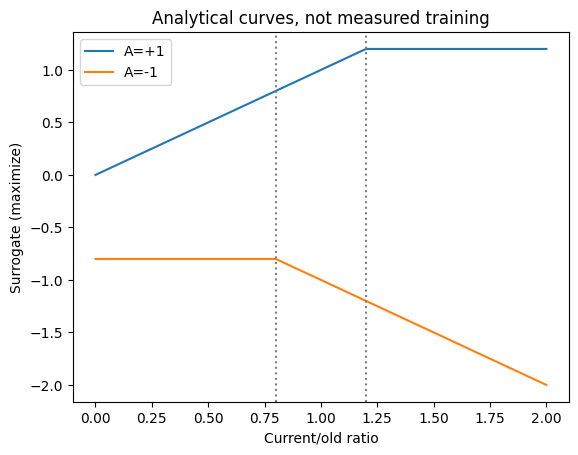

In [4]:
r=np.linspace(0,2,200)
plt.plot(r,np.minimum(r,np.clip(r,.8,1.2)),label='A=+1')
plt.plot(r,np.minimum(-r,-np.clip(r,.8,1.2)),label='A=-1')
plt.axvline(.8,color='gray',ls=':');plt.axvline(1.2,color='gray',ls=':');plt.legend();plt.xlabel('Current/old ratio');plt.ylabel('Surrogate (maximize)');plt.title('Analytical curves, not measured training');plt.show()
assert min(1.5*2,1.2*2)==2.4 and min(.5*-2,.8*-2)==-1.6

Mean of last 30 completed episode returns: 0.9800000000000001


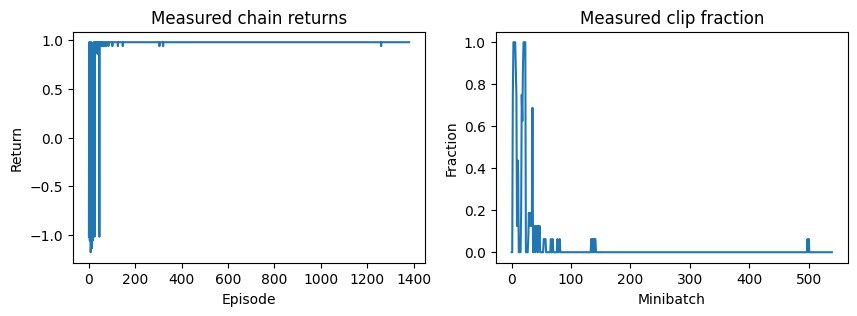

Greedy chain evaluation: 0.9800000000000001


In [5]:
model=ActorCritic();optimizer=torch.optim.Adam(model.parameters(),lr=.015)
env=Chain();state=env.reset();returns=[];losses=[];clipfractions=[];episode_return=0.
for iteration in range(45):
    states=[];actions=[];old_logps=[];values=[];next_values=[];rewards=[];ends=[];boundaries=[]
    # Store one recent rollout: the denominator is detached behavior logp, not reference logp.
    with torch.no_grad():
        for t in range(64):
            distribution,value=model(torch.tensor(state));action=distribution.sample()
            next_state,reward,terminated,truncated=env.step(action.item())
            _,next_value=model(torch.tensor(next_state))
            states.append(state);actions.append(action);old_logps.append(distribution.log_prob(action));values.append(value);next_values.append(next_value)
            rewards.append(reward);ends.append(terminated);boundaries.append(terminated or truncated)
            episode_return+=reward
            if terminated or truncated:returns.append(episode_return);episode_return=0.;state=env.reset()
            else:state=next_state
    old=torch.stack(old_logps);v=torch.stack(values)
    advantage,target=gae(torch.tensor(rewards),v,torch.stack(next_values),torch.tensor(ends),torch.tensor(boundaries))
    advantage=(advantage-advantage.mean())/(advantage.std(unbiased=False)+1e-8)
    states=torch.tensor(states);actions=torch.stack(actions)
    # Three optimization epochs, shuffled minibatches over the SAME rollout.
    for epoch in range(3):
        for idx in torch.randperm(64).split(16):
            distribution,value=model(states[idx]);ratio=(distribution.log_prob(actions[idx])-old[idx]).exp()
            unclipped=ratio*advantage[idx];clipped=ratio.clamp(.8,1.2)*advantage[idx]
            actor_loss=-torch.minimum(unclipped,clipped).mean()
            value_loss=.5*(value-target[idx]).square().mean();entropy=distribution.entropy().mean()
            loss=actor_loss+.5*value_loss-.01*entropy
            optimizer.zero_grad();loss.backward()
            assert torch.isfinite(loss) and all(torch.isfinite(p.grad).all() for p in model.parameters())
            nn.utils.clip_grad_norm_(model.parameters(),.5);optimizer.step()
            losses.append(loss.item());clipfractions.append(((ratio-1).abs()>.2).float().mean().item())
print('Mean of last 30 completed episode returns:',np.mean(returns[-30:]))
fig,axes=plt.subplots(1,2,figsize=(10,3));axes[0].plot(returns);axes[0].set(title='Measured chain returns',xlabel='Episode',ylabel='Return');axes[1].plot(clipfractions);axes[1].set(title='Measured clip fraction',xlabel='Minibatch',ylabel='Fraction');plt.show()
# Inference evaluation on new episodes without optimizer updates.
with torch.no_grad():
    evaluation=[]
    for _ in range(20):
        s=env.reset();total=0.
        while True:
            dist,_=model(torch.tensor(s));s,reward,done,trunc=env.step(dist.probs.argmax().item());total+=reward
            if done or trunc:break
        evaluation.append(total)
print('Greedy chain evaluation:',np.mean(evaluation))

## Stability checks

Old logps and old values are detached; every minibatch uses the same tokens/actions from that rollout. Gradient-norm clipping differs from surrogate clipping. Critic targets use raw advantages; actor normalization is later. True terminals suppress bootstrap; time-limit truncations keep final-observation value but stop recurrence across reset. Track clip fraction, value error, entropy and task returns. Performance here only describes this toy chain.

## Exercises

1. Increase update epochs and log approximate old/current KL.
2. Add optional value clipping and explain its target.
3. Sweep entropy coefficient; compare returns and exploration.

## Key takeaways

Recompute the worked examples, inspect masks and gradients, and evaluate independently of the training objective. A small training-loss decrease does not establish generalization or alignment. Record the model, data split, seeds and dependency versions before interpreting results.